# Shot Boundary Detection

A viewer of "Tears of Steel" searches the subtitles for Celia's line about her robot hand and
finds it at 5:47. A result that starts at 5:47 drops the viewer into the middle of the scene. The
natural edges of a result are the cuts that the editor of the film already made. This notebook
follows the book section *Shot Boundary Detection* on the film: we compute a brightness histogram
for each of its 17,620 frames, measure how much consecutive frames differ, choose a cut threshold
from the ROC curve, find gradual transitions with twin thresholds, and compare the result with
TransNet V2, a learned detector. At the end, the subtitle hit becomes a clip with proper edges.

**Learning goals:**
- See hard cuts and gradual transitions in the frames, and see why I-frames are only candidates
- Compare the pixel difference with the histogram distance on real frame pairs
- Choose a cut threshold from the distance distributions and the ROC curve of an annotated excerpt
- Detect gradual transitions with twin thresholds, on the book's toy example and on the film
- Measure precision and recall on a test excerpt, and look at the false and missed transitions
- Select keyframes for a shot, and compare the twin thresholds with TransNet V2

**Prerequisites:** Chapter 10, section *Color Features* (color histograms and the L1 distance);
Chapter 2, section on thresholds and the ROC curve

**Data:** "Tears of Steel" by the Blender Foundation (mango.blender.org), CC BY 3.0: the 720p
film (about 370 MB) and its English subtitles, downloaded on first run to
`data/tears_of_steel/`. The transitions of 0:00 to 6:00 are annotated in
`data/ch12/cut_annotation.json`.

**Run time:** the first run decodes the whole film twice (about one minute each) and runs
TransNet V2 on the CPU (about four minutes). Both results are cached, so later runs take seconds.

## Setup

`ch12_video.py` holds the plumbing: downloading and decoding the film with ffmpeg, caching, the
annotation, and the TransNet V2 model. The histograms, distances, thresholds, and the twin-threshold
rule are defined in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from shared.display import print_table, display_md
from ch12_video import (FPS, N_FRAMES, SMALL, ensure_film, decode, frames, keyframe_indices, cached,
                        tc, frame_of, load_annotation, evaluate, transnet_probabilities,
                        transnet_transitions, shots_from_transitions, parse_srt, show_frames)

ensure_film()                       # downloads the film and the subtitles on first run
annotation = load_annotation()
train, test = annotation["train"], annotation["test"]

display_md(
    f"| Film | Value |\n|---|---|\n"
    f"| Frames | {N_FRAMES:,} at {FPS} per second ({N_FRAMES / FPS / 60:.1f} minutes) |\n"
    f"| Training excerpt | {train['time']}: {len(train['transitions'])} annotated transitions |\n"
    f"| Test excerpt | {test['time']}: {len(test['transitions'])} annotated transitions |"
)

| Film | Value |
|---|---|
| Frames | 17,620 at 24 per second (12.2 minutes) |
| Training excerpt | 0:00-3:00: 35 annotated transitions |
| Test excerpt | 3:00-6:00: 41 annotated transitions |

## 1. Cuts and Transitions

### A hard cut and a dissolve

A hard cut switches from the last frame of one shot to the first frame of the next. A dissolve
fades the old shot out while the new shot fades in on top of it, so no single frame marks the
boundary. The annotation contains both. We show eight consecutive frames around a hard cut, and
every seventh frame of the two dissolves at 3:29.5.

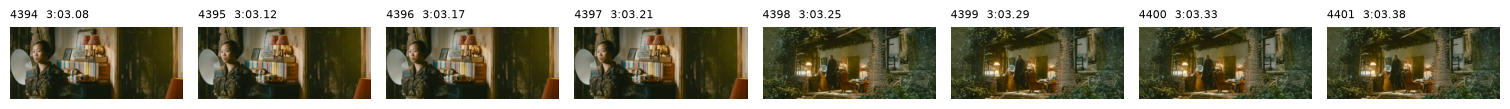

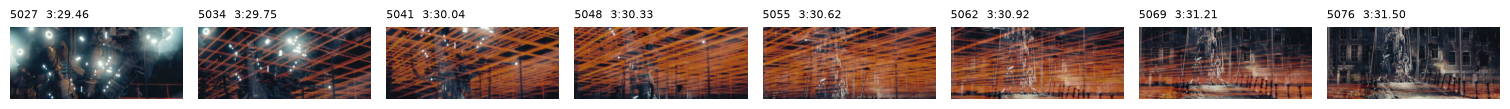

Hard cut between frames 4397 and 4398 (3:03.25). Dissolves: frames 5027 to 5046 (20 frames), frames 5047 to 5076 (30 frames)

In [2]:
cut = next(x for x in test["transitions"] if x["type"] == "cut")     # first hard cut of the test excerpt
start = cut["last"] - 4
show_frames(frames(start, 8), [f"{start + k}  {tc(start + k)}" for k in range(8)], ncols=8, width=1.9)

dissolves = [x for x in test["transitions"] if x["type"] == "gradual"]
first, last = dissolves[0]["first"], dissolves[-1]["last"]
step = 7
strip = frames(first, (last - first) // step + 1, step=step)
show_frames(strip, [f"{first + step * k}  {tc(first + step * k)}" for k in range(len(strip))], ncols=8, width=1.9)
display_md(
    f"Hard cut between frames {cut['first']} and {cut['last']} ({cut['time']}). "
    f"Dissolves: " + ", ".join(f"frames {x['first']} to {x['last']} ({x['last'] - x['first'] + 1} frames)"
                               for x in dissolves)
)

In the first strip, the image changes completely from one frame to the next. In the second strip,
the old and the new shot are visible at the same time for more than a second, and every single
step is small.

### I-frames: candidates, not boundaries

A video encoder stores most frames as differences to their neighbors and only some as complete
images, the I-frames. Encoders insert them at regular intervals and often at a detected scene
change. We ask ffmpeg for the I-frames of the film and compare them with the annotated cuts of
0:00 to 6:00.

In [3]:
iframes = keyframe_indices()
gaps, counts = np.unique(np.diff(iframes), return_counts=True)

annotated = train["transitions"] + test["transitions"]
cut_starts = {x["last"] for x in annotated if x["type"] == "cut"}    # first frame of each new shot
early = iframes[iframes < test["stop"]]
at_cut = sum(int(t) in cut_starts for t in early)

display_md(
    f"| I-frames | Value |\n|---|---|\n"
    f"| In the whole film | {len(iframes):,} |\n"
    f"| Most common gap | {gaps[counts.argmax()]} frames ({counts.max()} of {len(iframes) - 1} gaps) |\n"
    f"| In 0:00 to 6:00 | {len(early)} |\n"
    f"| ... at the first frame of a new shot | {at_cut} ({at_cut / len(early):.0%}) |\n"
    f"| Hard cuts in 0:00 to 6:00 | {len(cut_starts)} |\n"
    f"| ... that start with an I-frame | {at_cut} ({at_cut / len(cut_starts):.0%}) |"
)

| I-frames | Value |
|---|---|
| In the whole film | 997 |
| Most common gap | 18 frames (896 of 996 gaps) |
| In 0:00 to 6:00 | 488 |
| ... at the first frame of a new shot | 33 (7%) |
| Hard cuts in 0:00 to 6:00 | 73 |
| ... that start with an I-frame | 33 (45%) |

The encoder of this file stores an I-frame every 18 frames and inserts extra ones where it detects
a change. Most I-frames still lie inside shots, and fewer than half of the cuts start with an
I-frame. The encoder decides what is cheap to compress, not where a shot ends. I-frames are cheap
candidates; the boundaries must be found in the images.

## 2. Measuring the Change Between Frames

### The book's example: a cut from day to night

A brightness histogram records the share of the pixels in each brightness bin, regardless of where
the pixels lie. The book compares consecutive histograms with the L1 distance and computes it for
two frames of a daylight shot and for the cut to a night shot.

In [4]:
def l1(h, g):
    """L1 distance between histograms (along the last axis): 0 = same, 2 = no overlap."""
    return np.abs(np.asarray(h) - np.asarray(g)).sum(axis=-1)

day_1 = np.array([0.10, 0.20, 0.50, 0.20])      # h(t-1)
day_2 = np.array([0.12, 0.20, 0.47, 0.21])      # h(t)
night = np.array([0.60, 0.25, 0.10, 0.05])      # h(t+1)

display_md(
    f"- within the daylight shot: $d(t) = {l1(day_2, day_1):.2f}$\n"
    f"- across the cut: $d(t+1) = {l1(night, day_2):.2f}$, "
    f"{l1(night, day_2) / l1(day_2, day_1):.1f} times larger"
)

- within the daylight shot: $d(t) = 0.06$
- across the cut: $d(t+1) = 1.06$, 17.7 times larger

### Brightness histograms of all frames

For the film we use 32 brightness bins, computed on frames reduced to 320 by 134 pixels. The
histogram barely depends on the resolution, and the smaller frames decode much faster. The
function divides the brightness values 0 to 255 into 32 bins of 8 values each.

In [5]:
N_BINS = 32

def brightness_histogram(gray, n_bins=N_BINS):
    """Normalized brightness histogram of a gray image (values 0 to 255): shares that sum to 1."""
    return np.bincount(gray.ravel() // (256 // n_bins), minlength=n_bins) / gray.size

# one pass over the film; cached in data/tears_of_steel/hist_32.npy after the first run
hists = cached(f"hist_{N_BINS}", lambda: [brightness_histogram(g) for g in decode(SMALL, "gray")])
d = np.concatenate([[0.0], l1(hists[1:], hists[:-1])])      # d[t] = distance between frames t-1 and t

display_md(
    f"{len(hists):,} histograms with {hists.shape[1]} bins. Frame-to-frame distance $d(t)$: "
    f"median {np.median(d):.3f}, 99th percentile {np.percentile(d, 99):.3f}, maximum {d.max():.2f}."
)

17,620 histograms with 32 bins. Frame-to-frame distance $d(t)$: median 0.019, 99th percentile 0.325, maximum 2.00.

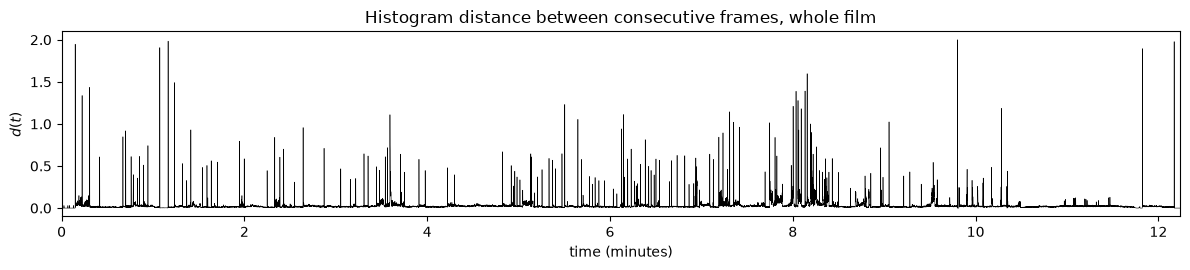

In [6]:
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.plot(np.arange(N_FRAMES) / FPS / 60, d, lw=0.4, color="black")
ax.set_xlabel("time (minutes)")
ax.set_ylabel("$d(t)$")
ax.set_title("Histogram distance between consecutive frames, whole film")
ax.set_xlim(0, N_FRAMES / FPS / 60)
plt.tight_layout()
plt.show()

Most of the curve stays close to zero, and the cuts stand out as spikes. The dense stretch
around 8:00 is the battle in the church, with explosions, muzzle flashes, and fast editing. From
about 10:20 on, the curve is flat: the end credits scroll by in one long shot.

### Pixel difference versus histogram distance

The pixel difference sums the change of every pixel: $d_{\text{pixel}}(t) = \sum_{x,y}
\|\mathbf{f}(x, y, t) - \mathbf{f}(x, y, t-1)\|_1$. We compute it for the RGB frames of the
training excerpt and divide by the number of pixels, so the value is the average change per pixel
(0 to 765). The two measures have different scales, so we compare how well each one separates the
annotated cuts from the frame pairs within shots. The frames inside the annotated fade belong to
neither group and are left out.

In [7]:
def pixel_differences(count):
    """Average L1 change of the RGB values per pixel between consecutive frames, for frames 0..count-1."""
    out, prev = [0.0], None
    for f in decode(SMALL, "rgb24", count=count):
        f = f.astype(np.int16)
        if prev is not None:
            out.append(np.abs(f - prev).sum(axis=2).mean())
        prev = f
    return np.array(out)

d_pixel = pixel_differences(train["stop"])

# frame pairs of the training excerpt: positives = annotated cuts, negatives = pairs within shots
in_gradual = np.zeros(N_FRAMES, bool)
for x in train["transitions"]:
    if x["type"] == "gradual":
        in_gradual[x["first"]:x["last"] + 1] = True
pairs = np.arange(1, train["stop"])
pairs = pairs[~in_gradual[pairs]]
train_cuts = [x["last"] for x in train["transitions"] if x["type"] == "cut"]
is_cut = np.isin(pairs, train_cuts)

def false_cuts_at(scores, n_found):
    """Threshold that finds n_found of the cuts, and the number of within-shot pairs above it."""
    T = np.sort(scores[is_cut])[::-1][n_found - 1]
    return T, int((scores[~is_cut] >= T).sum())

rows = []
for name, s in [("pixel difference", d_pixel[pairs]), ("histogram distance", d[pairs])]:
    T, fp = false_cuts_at(s, 30)
    rows.append([name, roc_auc_score(is_cut, s), s[~is_cut].max(), np.median(s[is_cut]), fp])
print_table(rows, ["Measure", "ROC area", "Largest within shot", "Median at a cut",
                   "False cuts at 30 of 34 cuts"], floatfmt=("", ".3f", ".3f", ".3f", ""))

| Measure            |   ROC area |   Largest within shot |   Median at a cut |   False cuts at 30 of 34 cuts |
|:-------------------|-----------:|----------------------:|------------------:|------------------------------:|
| pixel difference   |      0.924 |               122.693 |           169.435 |                             6 |
| histogram distance |      0.987 |                 0.397 |             0.610 |                             1 |

The histogram distance separates the two groups better: at the threshold that finds 30 of the 34
cuts, it reports fewer false cuts. Where does the pixel difference fail? We look at the within-shot
pair with the largest pixel difference.

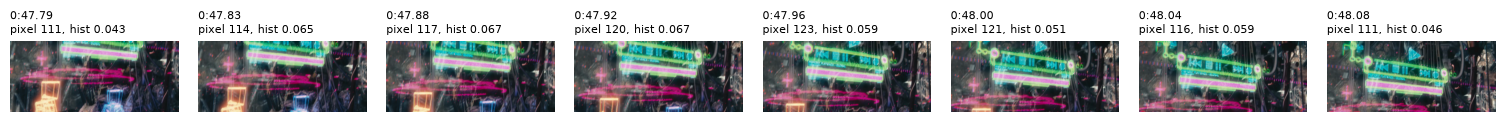

At 0:47.96, the pixel difference reaches 123, while the median at a cut is 169. The histogram distance of the same pair is 0.059, below its median at a cut by a factor of 10.

In [8]:
neg = pairs[~is_cut]
worst = int(neg[np.argmax(d_pixel[neg])])
start = worst - 4
show_frames(frames(start, 8), [f"{tc(start + k)}\npixel {d_pixel[start + k]:.0f}, hist {d[start + k]:.3f}"
                               for k in range(8)], ncols=8, width=1.9)
display_md(
    f"At {tc(worst)}, the pixel difference reaches {d_pixel[worst]:.0f}, while the median at a cut is "
    f"{np.median(d_pixel[train_cuts]):.0f}. The histogram distance of the same pair is {d[worst]:.3f}, "
    f"below its median at a cut by a factor of {np.median(d[train_cuts]) / d[worst]:.0f}."
)

The camera moves quickly across a wall of holographic displays. Inside this one shot, most
pixel values change from frame to frame, so the pixel difference reaches the size of a cut. The
pixels keep their brightness while they move, so the histogram barely changes.

## 3. Choosing the Threshold

A hard cut is declared when $d(t) \geq T$. The within-shot pairs form the negative class, the cuts
the positive class. We look at both distance distributions on the training excerpt, then sweep the
threshold and plot the ROC curve.

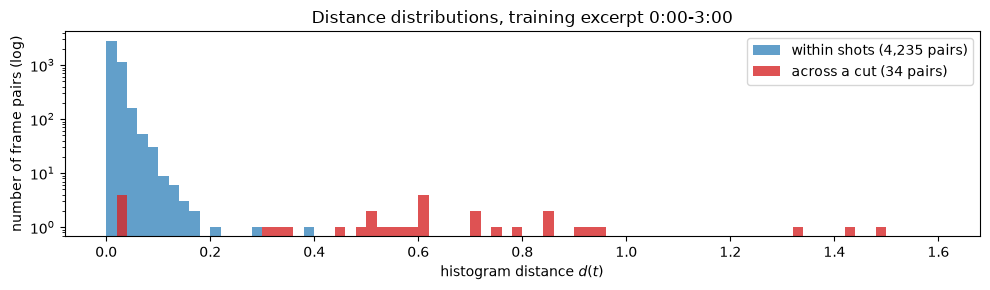

In [9]:
s_pos, s_neg = d[pairs][is_cut], d[pairs][~is_cut]

fig, ax = plt.subplots(figsize=(10, 3))
bins = np.linspace(0, 1.6, 81)
ax.hist(s_neg, bins=bins, color="tab:blue", alpha=0.7, label=f"within shots ({len(s_neg):,} pairs)")
ax.hist(s_pos, bins=bins, color="tab:red", alpha=0.8, label=f"across a cut ({len(s_pos)} pairs)")
ax.set_yscale("log")
ax.set_xlabel("histogram distance $d(t)$")
ax.set_ylabel("number of frame pairs (log)")
ax.set_title(f"Distance distributions, training excerpt {train['time']}")
ax.legend()
plt.tight_layout()
plt.show()

The two distributions overlap: a few cuts have tiny distances, and a few within-shot pairs reach
0.3 to 0.4. Every threshold trades missed cuts against false cuts. For retrieval, a missed cut costs
more than a false one, so we take the largest threshold that still reaches the highest recall on
the training excerpt.

In [10]:
thresholds = np.round(np.arange(0.05, 2.0, 0.01), 2)
tpr = np.array([(s_pos >= T).mean() for T in thresholds])
fpr = np.array([(s_neg >= T).mean() for T in thresholds])
T_c = float(thresholds[tpr == tpr.max()].max())

rows = [[T, int((s_pos >= T).sum()), int((s_neg >= T).sum()), (s_pos >= T).mean(), (s_neg >= T).mean()]
        for T in [0.1, 0.2, T_c, 0.4, 0.6, 0.8, 1.0]]
print_table(rows, ["Threshold T", f"Cuts found (of {len(s_pos)})", f"False cuts (of {len(s_neg):,})",
                   "True positive rate", "False positive rate"], floatfmt=("", "", "", ".3f", ".5f"))

|   Threshold T |   Cuts found (of 34) |   False cuts (of 4,235) |   True positive rate |   False positive rate |
|--------------:|---------------------:|------------------------:|---------------------:|----------------------:|
|           0.1 |                   30 |                      23 |                0.882 |               0.00543 |
|           0.2 |                   30 |                       3 |                0.882 |               0.00071 |
|           0.3 |                   30 |                       1 |                0.882 |               0.00024 |
|           0.4 |                   27 |                       0 |                0.794 |               0.00000 |
|           0.6 |                   19 |                       0 |                0.559 |               0.00000 |
|           0.8 |                   11 |                       0 |                0.324 |               0.00000 |
|           1.0 |                    6 |                       0 |                0.176 |               0.00000 |

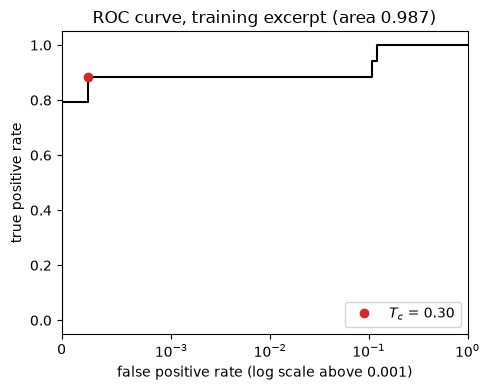

In [11]:
fp_curve, tp_curve, _ = roc_curve(is_cut, d[pairs])
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fp_curve, tp_curve, color="black")
k = int(np.flatnonzero(thresholds == T_c)[0])
ax.plot(fpr[k], tpr[k], "o", color="tab:red", label=f"$T_c$ = {T_c:.2f}")
ax.set_xscale("symlog", linthresh=1e-3)
ax.set_xlim(0, 1)
ax.set_xlabel("false positive rate (log scale above 0.001)")
ax.set_ylabel("true positive rate")
ax.set_title(f"ROC curve, training excerpt (area {roc_auc_score(is_cut, d[pairs]):.3f})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The curve rises almost vertically: at $T_c = 0.30$, the detector finds 30 of the 34 cuts with a
single false cut. Below 0.30, more false cuts appear and no further cut is found. Which four cuts
does no reasonable threshold find?

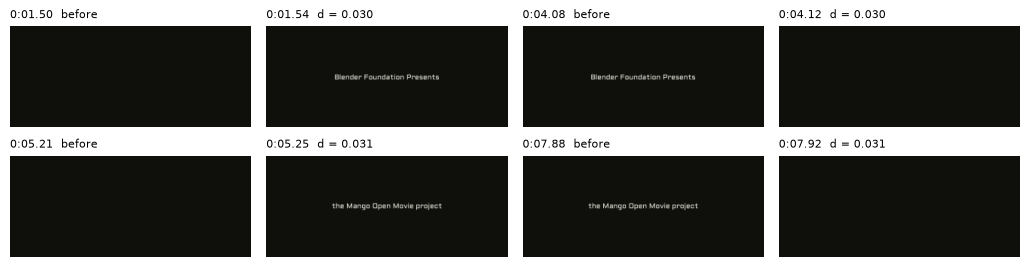

In [12]:
missed_cuts = [t for t in train_cuts if d[t] < T_c]
show_frames([frames(t - 1, 2)[k] for t in missed_cuts for k in (0, 1)],
            [f"{tc(t - 1 + k)}  d = {d[t]:.3f}" if k else f"{tc(t - 1)}  before" for t in missed_cuts for k in (0, 1)],
            ncols=4, width=2.6)

All four lead into or out of title cards: small text on black, whose brightness histogram differs
little from the black frames around it. This is the blind spot of the histogram: two different
images with nearly the same distribution of light and dark.

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">One threshold does not fit all videos</strong><br>
$T_c = 0.30$ fits this film with 32 brightness bins. A music video or a dark thriller has other distance distributions. Choose the threshold on a sample of the target collection, or use an adaptive threshold that compares $d(t)$ with the distances of the surrounding frames.
</div>

## 4. Gradual Transitions and Twin Thresholds

### The rule

Twin thresholding adds a lower threshold $T_s$ for the possible start of a gradual transition. It
remembers the last frame before the change as the reference $r$, follows the change while the
consecutive distances stay at or above $T_s$, and then compares the end frame $e$ with the
reference: if $\delta_{L1}(\mathbf{h}(e), \mathbf{h}(r)) \geq T_c$, the frames $r$ to $e$ form a
gradual transition.

In [13]:
def twin_thresholds(hists, d, T_c, T_s):
    """Twin comparison: hard cuts, gradual transitions (r, e, distance), and rejected candidates."""
    cuts, graduals, rejected = [], [], []
    t, n = 1, len(d)
    while t < n:
        if d[t] >= T_c:                       # 1. hard cut between t-1 and t
            cuts.append(t)
            t += 1
        elif d[t] >= T_s:                     # 2. possible start: reference = last frame before the change
            r, e = t - 1, t
            while e + 1 < n and T_s <= d[e + 1] < T_c:
                e += 1                        # 3. the content keeps changing
            total = float(l1(hists[e], hists[r]))     # 4. compare the end frame with the reference
            (graduals if total >= T_c else rejected).append((r, e, total))
            t = e + 1
        else:
            t += 1
    return cuts, graduals, rejected

### The book's dissolve

The book turns the cut from day to night into a dissolve of five frames, in which the histogram
moves in five equal steps. Frame 1 is the last daylight frame, frames 2 to 6 form the dissolve, and
frames 7 and 8 belong to the night shot. The same function must find it.

In [14]:
toy = np.array([day_2, day_2] + [day_2 + k / 5 * (night - day_2) for k in range(1, 6)] + [night, night])
toy_d = np.concatenate([[0.0], l1(toy[1:], toy[:-1])])
toy_cuts, toy_grads, _ = twin_thresholds(toy, toy_d, T_c=0.8, T_s=0.15)

print_table([[t, toy_d[t], l1(toy[t], toy[1])] for t in range(2, 8)],
            ["Frame t", "d(t)", "Distance to reference frame 1"], floatfmt=("", ".3f", ".3f"))
display_md(f"Hard cuts: {toy_cuts or 'none'}. Gradual transitions (r, e, distance): "
           + ", ".join(f"({r}, {e}, {s:.2f})" for r, e, s in toy_grads))

|   Frame t |   d(t) |   Distance to reference frame 1 |
|----------:|-------:|--------------------------------:|
|         2 |  0.212 |                           0.212 |
|         3 |  0.212 |                           0.424 |
|         4 |  0.212 |                           0.636 |
|         5 |  0.212 |                           0.848 |
|         6 |  0.212 |                           1.060 |
|         7 |  0.000 |                           1.060 |

Hard cuts: none. Gradual transitions (r, e, distance): (1, 6, 1.06)

No consecutive distance exceeds 0.212, yet the comparison with the reference frame recovers the
full change of 1.06, and frames 1 to 6 are reported as one gradual transition.

### On the film

The book sets $T_s$ to the 99th percentile of the within-shot distances of the training excerpt,
so that 1% of the within-shot pairs open a candidate.

In [15]:
T_s = float(np.round(np.percentile(s_neg, 99), 2))
cuts, graduals, rejected = twin_thresholds(hists, d, T_c, T_s)

display_md(
    f"$T_c = {T_c:.2f}$, $T_s = {T_s:.2f}$. Over the whole film, the twin thresholds report "
    f"**{len(cuts)} hard cuts** and **{len(graduals)} gradual transitions**, and reject "
    f"{len(rejected)} candidates whose end frame stayed close to the reference frame."
)

$T_c = 0.30$, $T_s = 0.08$. Over the whole film, the twin thresholds report **190 hard cuts** and **43 gradual transitions**, and reject 190 candidates whose end frame stayed close to the reference frame.

## 5. Evaluation on the Test Excerpt

Thresholds chosen on 0:00 to 3:00 are now tested on 3:00 to 6:00, which has 39 annotated hard cuts
and 2 dissolves. A hard cut counts as found if a detection lies within two frames of it, a gradual
transition if a detection overlaps it.

In [16]:
lo, hi = test["first"], test["stop"]
twin = evaluate(cuts, [(r, e) for r, e, _ in graduals], test["transitions"], lo, hi)

def result_rows(results):
    keys = [("Reported transitions", "reported"), ("Correct", "correct"), ("False", "false"),
            ("Missed", "missed"), ("Precision", "precision"), ("Recall", "recall"), ("F1", "f1")]
    return [[label] + [f"{r[k]:.2f}" if isinstance(r[k], float) else r[k] for r in results] for label, k in keys]

print_table(result_rows([twin]), ["", "Twin thresholds"])

|                      |   Twin thresholds |
|:---------------------|------------------:|
| Reported transitions |             52    |
| Correct              |             35    |
| False                |             17    |
| Missed               |              6    |
| Precision            |              0.67 |
| Recall               |              0.85 |
| F1                   |              0.75 |

### What the false detections are

In [17]:
false = twin["false_list"]
print_table([[tc(a), tc(b), kind, f"{d[b]:.3f}"] for a, b, kind in false],
            ["From", "To", "Type", "d(t) at the last frame"])

| From    | To      | Type    |   d(t) at the last frame |
|:--------|:--------|:--------|-------------------------:|
| 3:35.54 | 3:35.58 | cut     |                    0.745 |
| 3:35.58 | 3:35.62 | cut     |                    0.691 |
| 3:35.62 | 3:35.67 | cut     |                    0.428 |
| 3:35.75 | 3:35.79 | cut     |                    0.403 |
| 3:35.79 | 3:35.83 | cut     |                    0.438 |
| 3:35.83 | 3:35.88 | cut     |                    0.326 |
| 3:35.88 | 3:36.33 | gradual |                    0.106 |
| 3:42.79 | 3:42.96 | gradual |                    0.159 |
| 3:43.00 | 3:43.17 | gradual |                    0.093 |
| 5:07.96 | 5:08.00 | cut     |                    0.645 |
| 5:08.04 | 5:08.08 | cut     |                    0.584 |
| 5:08.12 | 5:08.17 | cut     |                    0.595 |
| 5:08.21 | 5:08.25 | cut     |                    0.579 |
| 5:08.29 | 5:08.33 | cut     |                    0.596 |
| 5:08.38 | 5:08.42 | cut     |                    0.608 |
| 5:08.46 | 5:08.50 | cut     |                    0.598 |
| 5:28.46 | 5:28.50 | cut     |                    0.445 |

The false detections cluster at a few moments. We show two of them: the bright glow that follows
the cut at 3:35.5, and the hologram at 5:08 that flickers every second frame.

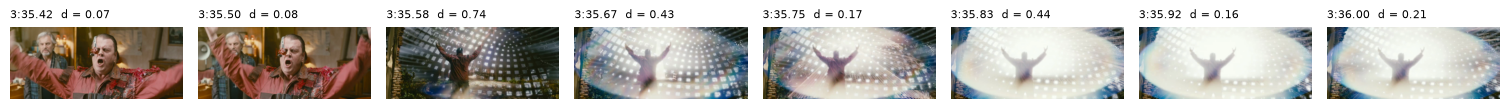

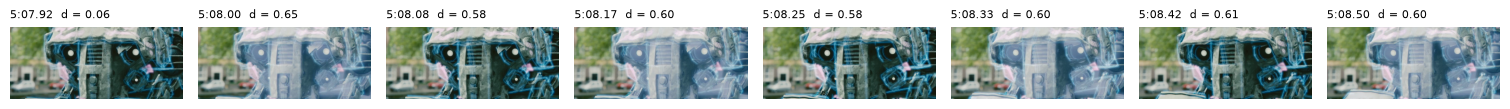

In [18]:
for start in (frame_of("3:35.4"), frame_of("5:07.9")):
    show_frames(frames(start, 8, step=2), [f"{tc(start + 2 * k)}  d = {d[start + 2 * k]:.2f}" for k in range(8)],
                ncols=8, width=1.9)

Neither event replaces the content of the shot. The glow and the flicker change the brightness
of most pixels within a frame or two, and that is all a brightness histogram sees: the same
weakness as a camera flash.

### Why the two dissolves are missed

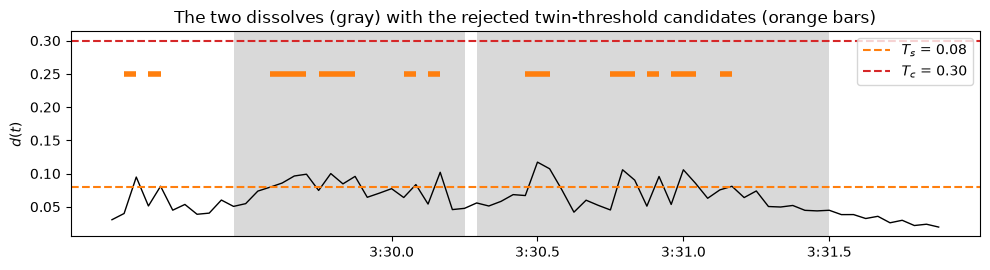

Inside the dissolves, $d(t)$ ranges from 0.04 to 0.12, and 68% of the steps fall below $T_s$.

In [19]:
a, b = dissolves[0]["first"] - 10, dissolves[-1]["last"] + 10
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(np.arange(a, b) / FPS, d[a:b], color="black", lw=1)
for x in dissolves:
    ax.axvspan(x["first"] / FPS, x["last"] / FPS, color="0.85", lw=0)
ax.axhline(T_s, color="tab:orange", ls="--", label=f"$T_s$ = {T_s:.2f}")
ax.axhline(T_c, color="tab:red", ls="--", label=f"$T_c$ = {T_c:.2f}")
for r, e, total in rejected:
    if a <= e < b:
        ax.plot([r / FPS, e / FPS], [0.25, 0.25], color="tab:orange", lw=4, solid_capstyle="butt")
ax.set_xticks(np.arange(np.ceil(a / FPS), b / FPS, 0.5))
ax.set_xticklabels([tc(int(s * FPS))[:-1] for s in np.arange(np.ceil(a / FPS), b / FPS, 0.5)])
ax.set_ylabel("$d(t)$")
ax.set_title("The two dissolves (gray) with the rejected twin-threshold candidates (orange bars)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

inside = d[dissolves[0]["first"]:dissolves[-1]["last"] + 1]
display_md(f"Inside the dissolves, $d(t)$ ranges from {inside.min():.2f} to {inside.max():.2f}, and "
           f"{(inside < T_s).mean():.0%} of the steps fall below $T_s$.")

The consecutive distance swings around $T_s$. Each time it drops below $T_s$, the candidate ends
after a few frames and compares only a fragment of the dissolve with the reference frame. Every
fragment stays below $T_c$, so every candidate is rejected.

## 6. Keyframes

Each shot needs keyframes that represent it in the index. We take the shots between the
twin-threshold detections and pick the one around 4:30: for half a minute, Thom walks across a
bridge and along a canal, and the camera follows him. Three simple choices: the first frame, the middle frame, and
the most representative frame, the one whose histogram lies closest to the mean histogram of the
shot.

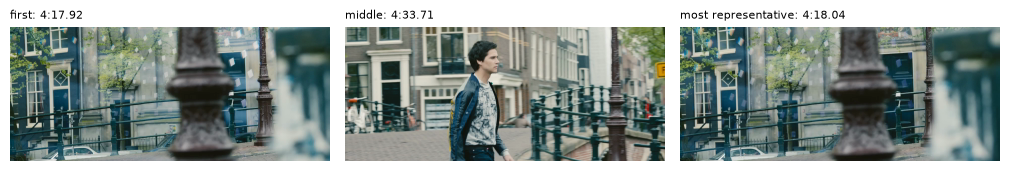

The shot runs from 4:17.92 to 4:49.50 (31.6 seconds).

In [20]:
bounds = sorted(set([0] + cuts + [e + 1 for _, e, _ in graduals] + [N_FRAMES]))
t_walk = frame_of("4:30")
shot_start = max(b for b in bounds if b <= t_walk)
shot_end = min(b for b in bounds if b > t_walk) - 1
shot = hists[shot_start:shot_end + 1]

middle = (shot_start + shot_end) // 2
representative = shot_start + int(np.argmin(l1(shot, shot.mean(axis=0))))
choices = [("first", shot_start), ("middle", middle), ("most representative", representative)]
show_frames([frames(t, 1)[0] for _, t in choices], [f"{name}: {tc(t)}" for name, t in choices], width=3.4)
display_md(f"The shot runs from {tc(shot_start)} to {tc(shot_end)} ({(shot_end - shot_start + 1) / FPS:.1f} seconds).")

The middle frame shows Thom. The most representative frame is a blurred view of a lamp post and a
railing from the first second, before Thom appears: its distribution of light and dark happens to
lie closest to the average of the shot. A brightness histogram knows how light and dark a frame
is, not what it shows. And no single frame can show half a minute in which the street, the canal, and finally a
robot appear. Clustering the frame histograms with $k$-means and taking the frame closest to each cluster center
gives one keyframe per visually distinct part of the shot.

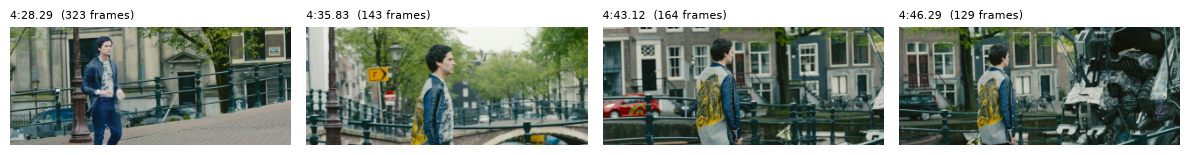

In [21]:
from sklearn.cluster import KMeans

def cluster_keyframes(shot_hists, first_frame, k=4):
    """One keyframe per k-means cluster of the frame histograms: the frame closest to each center."""
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(shot_hists)
    picks = [first_frame + int(np.argmin(l1(shot_hists, c))) for c in km.cluster_centers_]
    sizes = np.bincount(km.labels_, minlength=k)
    return sorted(zip(picks, sizes))

picks = cluster_keyframes(shot, shot_start)
show_frames([frames(t, 1)[0] for t, _ in picks], [f"{tc(t)}  ({n} frames)" for t, n in picks], width=3.0)

## 7. Then vs. Now: TransNet V2

TransNet V2 (Souček and Lokoč, 2020) downscales every frame to 48 by 27 pixels, processes windows
of 100 frames with convolutions over space and time, and outputs for each frame the probability of
a transition. We use the published weights and report a transition wherever the probability
exceeds 0.5.

In [22]:
p, seconds = transnet_probabilities()     # cached after the first run
runs = transnet_transitions(p, threshold=0.5)

# a run of one frame (s, s) is a hard cut at s + 1, a longer run a gradual transition from s to e + 1
tn = evaluate([s + 1 for s, e in runs if e == s], [(s, e + 1) for s, e in runs if e > s],
              test["transitions"], lo, hi)
print_table(result_rows([twin, tn]), ["", "Twin thresholds", "TransNet V2"])
display_md(
    f"Over the whole film, TransNet V2 finds {len(runs)} transitions ({len(runs) + 1} shots); the longest "
    f"run above 0.5 has {max(e - s + 1 for s, e in runs)} frame(s). It processed the {N_FRAMES:,} frames in "
    f"{seconds:.0f} seconds on a CPU, {N_FRAMES / seconds:.0f} frames per second."
)

|                      |   Twin thresholds |   TransNet V2 |
|:---------------------|------------------:|--------------:|
| Reported transitions |             52    |         38    |
| Correct              |             35    |         38    |
| False                |             17    |          0    |
| Missed               |              6    |          3    |
| Precision            |              0.67 |          1    |
| Recall               |              0.85 |          0.93 |
| F1                   |              0.75 |          0.96 |

Over the whole film, TransNet V2 finds 139 transitions (140 shots); the longest run above 0.5 has 1 frame(s). It processed the 17,620 frames in 214 seconds on a CPU, 82 frames per second.

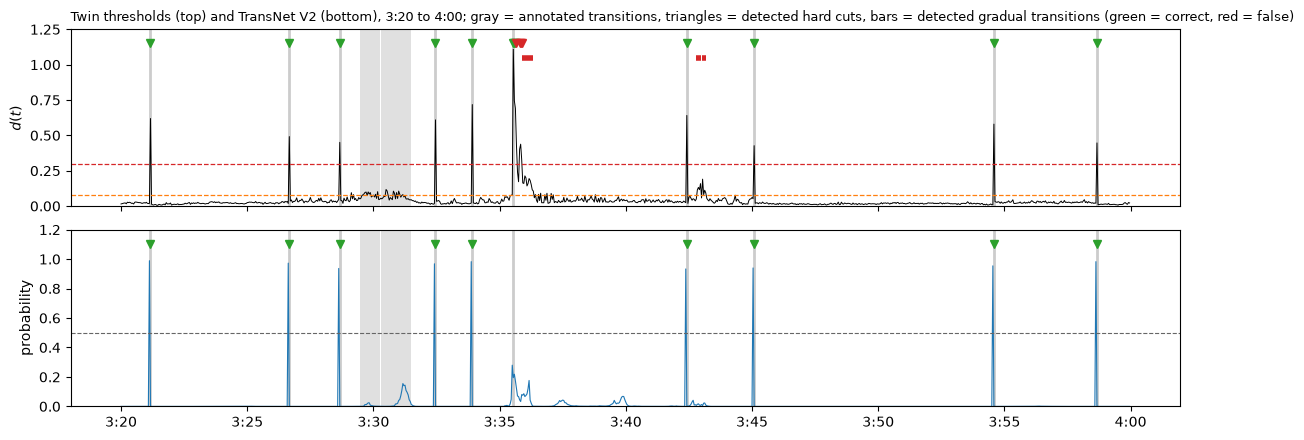

Highest TransNet V2 probability at the cut into the glow (3:35.54): 0.28. Inside the dissolves: 0.15.

In [23]:
a, b = frame_of("3:20"), frame_of("4:00")
true_cuts = [x["last"] for x in test["transitions"] if x["type"] == "cut" and a <= x["last"] < b]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
for ax in (ax1, ax2):
    for t in true_cuts:
        ax.axvline(t / FPS, color="0.8", lw=2, zorder=0)
    for x in dissolves:
        ax.axvspan(x["first"] / FPS, x["last"] / FPS, color="0.88", lw=0, zorder=0)
ax1.plot(np.arange(a, b) / FPS, d[a:b], color="black", lw=0.7)
ax1.axhline(T_c, color="tab:red", ls="--", lw=0.9)
ax1.axhline(T_s, color="tab:orange", ls="--", lw=0.9)
for t in cuts:
    if a <= t < b:
        ax1.plot(t / FPS, 1.15, "v", color="tab:green" if any(abs(t - u) <= 2 for u in true_cuts) else "tab:red")
for r, e, _ in graduals:
    if a <= e < b:
        ok = any(r - 2 <= x["last"] and x["first"] <= e + 2 for x in test["transitions"])
        ax1.plot([r / FPS, e / FPS], [1.05, 1.05], color="tab:green" if ok else "tab:red", lw=4, solid_capstyle="butt")
ax1.set_ylim(0, 1.25)
ax1.set_ylabel("$d(t)$")
ax1.set_title("Twin thresholds (top) and TransNet V2 (bottom), 3:20 to 4:00; gray = annotated "
              "transitions, triangles = detected hard cuts, bars = detected gradual transitions (green = correct, red = false)",
              loc="left", fontsize=9)
ax2.plot(np.arange(a, b) / FPS, p[a:b], color="tab:blue", lw=0.8)
ax2.axhline(0.5, color="0.4", ls="--", lw=0.8)
for s, e in runs:
    if a <= s < b:
        ax2.plot((s + 1) / FPS, 1.1, "v", color="tab:green" if any(abs(s + 1 - t) <= 2 for t in true_cuts) else "tab:red")
ax2.set_ylim(0, 1.2)
ax2.set_ylabel("probability")
ticks = np.arange(a / FPS, b / FPS + 1, 5)
ax2.set_xticks(ticks)
ax2.set_xticklabels([tc(int(t * FPS))[:-3] for t in ticks])
plt.tight_layout()
plt.show()

glow_cut = next(t for t in true_cuts if abs(t - frame_of("3:35.5")) <= 2)
display_md(f"Highest TransNet V2 probability at the cut into the glow ({tc(glow_cut)}): "
           f"{p[glow_cut - 3:glow_cut + 2].max():.2f}. Inside the dissolves: {p[dissolves[0]['first']:dissolves[-1]['last'] + 1].max():.2f}.")

TransNet V2 reports nothing at the glow and the flicker: it has seen a window of 100 frames and
has learned that a light effect does not replace the content. It misses the cut into the glow
itself, and, like the twin thresholds, both dissolves. Gradual transitions remain the hard case
for both generations.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">The learned detector moves the threshold, it does not remove it</strong><br>
On the test excerpt, TransNet V2 reports no false transitions where the twin thresholds report 17, most of them light effects inside shots. Both miss the dissolves. The network still outputs a probability per frame, and choosing 0.5 trades missed cuts against false cuts in the same way as choosing $T_c$.
</div>

## Payoff: From a Subtitle Hit to a Clip

The chapter starts with the line "Why don't you just admit that you're freaked out by my robot
hand?". The subtitles give us its time, the shots give us the edges of the result. We find the
subtitles that contain "robot hand" and return every TransNet V2 shot that overlaps them.

| Subtitle           |   Shots | Clip               | Length   |
|:-------------------|--------:|:-------------------|:---------|
| 0:30.79 to 0:34.00 |       1 | 0:25.00 to 0:40.21 | 15.2 s   |
| 5:47.00 to 5:50.00 |       2 | 5:46.46 to 5:50.17 | 3.8 s    |

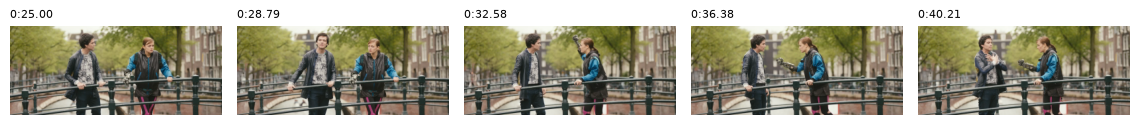

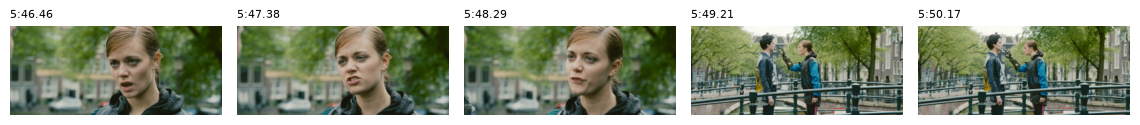

In [24]:
shots = shots_from_transitions(runs)
rows, clips = [], []
for start_s, end_s, text in parse_srt():
    if "robot hand" in text.lower():
        hit = [(a, b) for a, b in shots if a <= end_s * FPS and b >= start_s * FPS]
        clips.append((hit[0][0], hit[-1][1]))
        rows.append([f"{tc(int(start_s * FPS))} to {tc(int(end_s * FPS))}", len(hit),
                     f"{tc(hit[0][0])} to {tc(hit[-1][1])}", f"{(hit[-1][1] - hit[0][0] + 1) / FPS:.1f} s"])
print_table(rows, ["Subtitle", "Shots", "Clip", "Length"])

for a, b in clips:
    picks = np.linspace(a, b, 5).astype(int)
    show_frames([frames(int(t), 1)[0] for t in picks], [tc(int(t)) for t in picks], width=2.3)

The first hit lies inside one long shot on the bridge, so the clip covers the whole conversation
in that shot. The second hit crosses a cut, so its clip joins two short shots. The shot gives a
result its edges, but a shot is not yet a scene: the replay at 5:47 belongs to a longer exchange,
and grouping shots into scenes needs more than one distance threshold.

## Summary

- A hard cut changes the image from one frame to the next; a dissolve spreads the change over
  dozens of frames. I-frames are cheap candidates, but most of them lie inside shots, and fewer
  than half of the cuts of this film start with one.
- The histogram distance ignores where the pixels lie, so motion inside a shot barely changes it.
  The pixel difference reacts to fast motion as strongly as to a cut.
- The threshold comes from the distance distributions of an annotated excerpt. On "Tears of
  Steel", $T_c = 0.30$ finds 30 of 34 training cuts with one false cut; the four misses are title
  cards on black.
- Twin thresholds recover the book's dissolve, but on the film they react to glows and flickers
  and miss the two real dissolves, whose steps swing around $T_s$.
- TransNet V2 removes the false detections on the test excerpt and still misses the dissolves.
  Its probabilities need a threshold too.

## Try it yourself

1. **An adaptive threshold.** Replace the fixed $T_c$ by a local one: declare a cut where $d(t)$
   exceeds the mean of the 24 surrounding distances by $k$ standard deviations. Evaluate it on the
   test excerpt for $k = 3, 5, 8$. Does it remove the false cuts in the glow and the flicker?
2. **Color instead of brightness.** Compute an RGB histogram with $8 \times 8 \times 8$ bins
   instead of 32 brightness bins (use `decode(SMALL, "rgb24")` and a cache name of your own), and
   repeat the ROC analysis. Does it find the four title-card cuts?
3. **A lower TransNet V2 threshold.** Call `transnet_transitions(p, threshold=0.2)` and evaluate
   again. Which transitions does it find now, and what does it cost in false detections?